# 03 · Visualizaciones finales

**Objetivo:** con los datos limpios, construir los **4-6 gráficos** que responden a las preguntas del Business Understanding (sección 1 de `REPORT.md`) y pulirlos. No van aquí todos los gráficos de la exploración.

Checklist de cada gráfico:
- [x] Responde a una pregunta concreta del REPORT
- [x] El título cuenta la conclusión, no solo describe
- [x] Ejes con nombre y unidades
- [x] Color con intención: lo importante en `DESTACADO`, el resto en `GRIS`
- [x] Nada que sobre: sin bordes ni leyendas innecesarias; identidad con etiquetas directas, no solo con color

**Historia del video:** *Same demography, different paths.* Las cuatro figuras siguen el orden del guion. El texto va en inglés, como recomendó la coordinación de la competencia. Formato 16:9 para el video.

| Figura | Mensaje |
|---|---|
| Fig 01 | La transición demográfica fue la misma en los 8 países |
| Fig 02 | La desigualdad de aprendizaje siguió caminos distintos según la materia y el país |
| Fig 03 | Solo Perú cerró la brecha desde abajo, en las tres materias |
| Fig 04 | Parte de la caída es por mayor cobertura, y el cambio demográfico no predice el cambio de la brecha |

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))  # permite importar src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src.utils import cargar_processed
from src.estilo import aplicar_estilo, guardar_figura, PALETA, DESTACADO, GRIS, TEXTO_SECUNDARIO, TEXTO_SUAVE

aplicar_estilo()

al = cargar_processed("al_wpp_1950_2100.csv")
panel = cargar_processed("al_panel_pisa.csv")
cambios = cargar_processed("al_cambios_2009_2025.csv")

TAMANO = (12.8, 7.2)  # 16:9 para el video
MATERIA_EN = {"Matematicas": "Mathematics", "Lectura": "Reading", "Ciencias": "Science"}
MATERIAS = list(MATERIA_EN)
OSCURO = "#52514e"
FUENTE = "Sources: UN World Population Prospects 2024; OECD, PISA 2025 Results (Vol. I), trend tables I.B1.2a.33–41 and A2.1."


def pie(fig, texto=FUENTE, y=0.005):
    fig.text(0.01, y, texto, fontsize=9, color=TEXTO_SUAVE, ha="left", va="bottom")


def subtitulo(fig, texto, y=0.915):
    fig.text(0.01, y, texto, fontsize=12, color=TEXTO_SECUNDARIO, ha="left", va="top")

## Fig 01 · La misma transición demográfica

Fecundidad y mortalidad infantil de 1950 a 2050 en los 8 países (gris) y la región (negro). Desde 2024 son proyecciones de la ONU, con su intervalo de predicción del 80 % y 95 % para la región.

Figura guardada: figures\fig01_misma_demografia.png


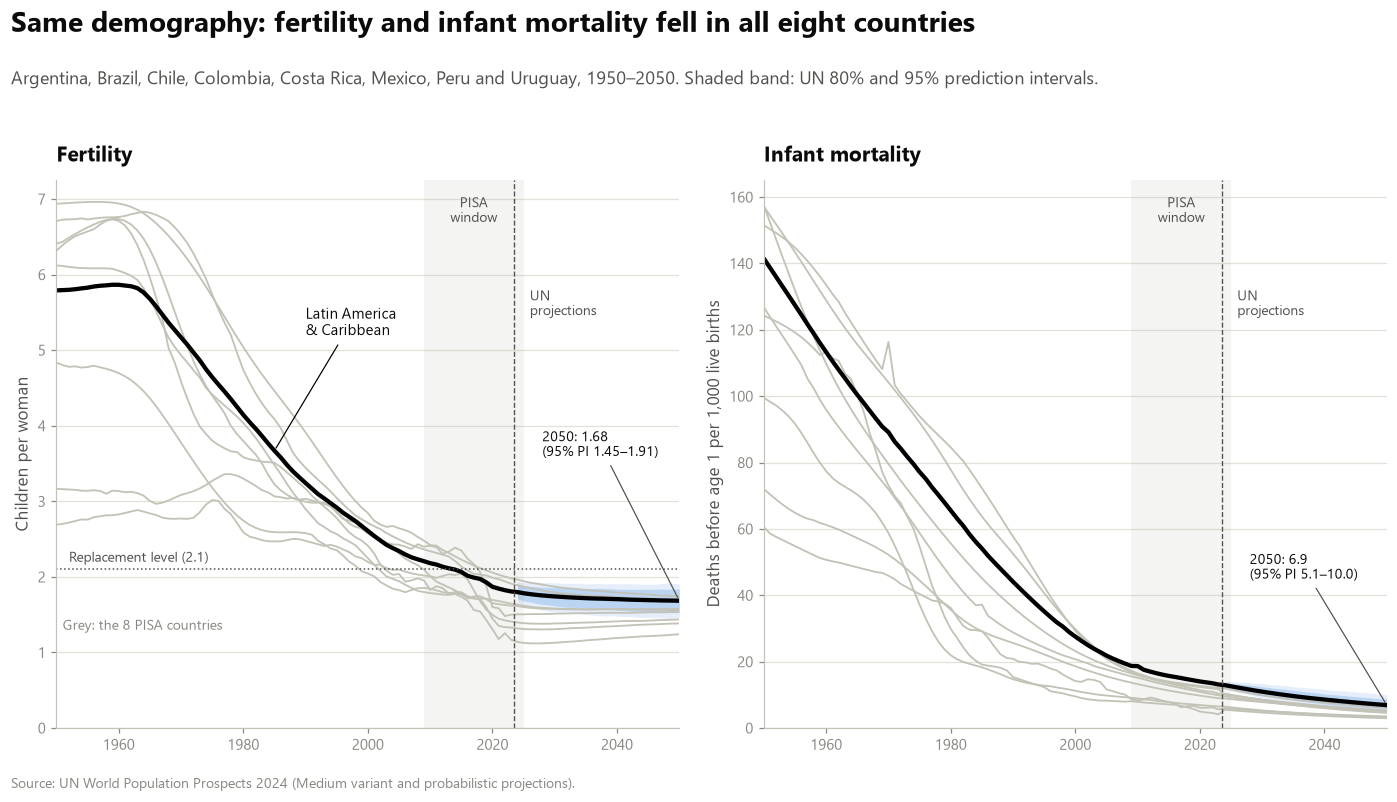

In [2]:
fig, axes = plt.subplots(1, 2, figsize=TAMANO)
paises = sorted(panel["Pais"].unique())
region = al.loc[al["ISO3_code"].eq("AL_REGION") & al["Time"].le(2050)]
for ax, ind, titulo, unidad in zip(
    axes, ["TFR", "IMR"],
    ["Fertility", "Infant mortality"],
    ["Children per woman", "Deaths before age 1 per 1,000 live births"],
):
    ax.axvspan(2009, 2025, color=GRIS, alpha=0.18, lw=0)
    for pais in paises:
        d = al.loc[al["Location"].eq(pais) & al["Time"].le(2050)]
        ax.plot(d["Time"], d[ind], color=GRIS, lw=1.2)
    proy = region.loc[region["Time"] >= 2024]
    ax.fill_between(proy["Time"], proy[f"{ind}_PI95_inf"], proy[f"{ind}_PI95_sup"], color=DESTACADO, alpha=0.12, lw=0)
    ax.fill_between(proy["Time"], proy[f"{ind}_PI80_inf"], proy[f"{ind}_PI80_sup"], color=DESTACADO, alpha=0.22, lw=0)
    ax.plot(region["Time"], region[ind], color="black", lw=2.8)
    ax.axvline(2023.5, color=OSCURO, ls="--", lw=0.9)
    ax.set_xlim(1950, 2050)
    ax.set_ylim(0, None)
    ax.set_title(titulo, fontsize=14)
    ax.set_ylabel(unidad)
    tope = ax.get_ylim()[1]
    ax.text(2017, tope * 0.97, "PISA\nwindow", ha="center", va="top", fontsize=9, color=OSCURO)
    ax.text(2026, tope * 0.80, "UN\nprojections", ha="left", va="top", fontsize=9, color=OSCURO)

axes[0].axhline(2.1, color=OSCURO, ls=":", lw=1)
axes[0].text(1952, 2.2, "Replacement level (2.1)", fontsize=9, color=OSCURO)
fin_r = region.set_index("Time")
axes[0].annotate("Latin America\n& Caribbean", (1985, fin_r.loc[1985, "TFR"]), xytext=(1990, 5.2),
                 fontsize=10, arrowprops=dict(arrowstyle="-", color="black", lw=0.8))
axes[0].text(1951, 1.3, "Grey: the 8 PISA countries", fontsize=9, color=TEXTO_SUAVE)
axes[1].annotate(f"2050: {fin_r.loc[2050, 'IMR']:.1f}\n(95% PI {fin_r.loc[2050, 'IMR_PI95_inf']:.1f}–{fin_r.loc[2050, 'IMR_PI95_sup']:.1f})",
                 (2050, fin_r.loc[2050, "IMR"]), xytext=(2028, 45), fontsize=9,
                 arrowprops=dict(arrowstyle="-", color=OSCURO, lw=0.8))
axes[0].annotate(f"2050: {fin_r.loc[2050, 'TFR']:.2f}\n(95% PI {fin_r.loc[2050, 'TFR_PI95_inf']:.2f}–{fin_r.loc[2050, 'TFR_PI95_sup']:.2f})",
                 (2050, fin_r.loc[2050, "TFR"]), xytext=(2028, 3.6), fontsize=9,
                 arrowprops=dict(arrowstyle="-", color=OSCURO, lw=0.8))

fig.suptitle("Same demography: fertility and infant mortality fell in all eight countries", x=0.01, ha="left", fontsize=18, fontweight="bold", y=0.99)
subtitulo(fig, "Argentina, Brazil, Chile, Colombia, Costa Rica, Mexico, Peru and Uruguay, 1950–2050. Shaded band: UN 80% and 95% prediction intervals.")
pie(fig, "Source: UN World Population Prospects 2024 (Medium variant and probabilistic projections).")
fig.tight_layout(rect=(0, 0.03, 1, 0.9))
_ = guardar_figura(fig, "fig01_misma_demografia")

## Fig 02 · Caminos distintos

Cada punto es un país: cuánto cambió su percentil 10 (los rezagados) y su percentil 90 (los mejores) entre 2009 y 2025, según la OCDE. Debajo de la diagonal, la brecha se cerró; encima, se abrió.

Figura guardada: figures\fig02_caminos_distintos.png


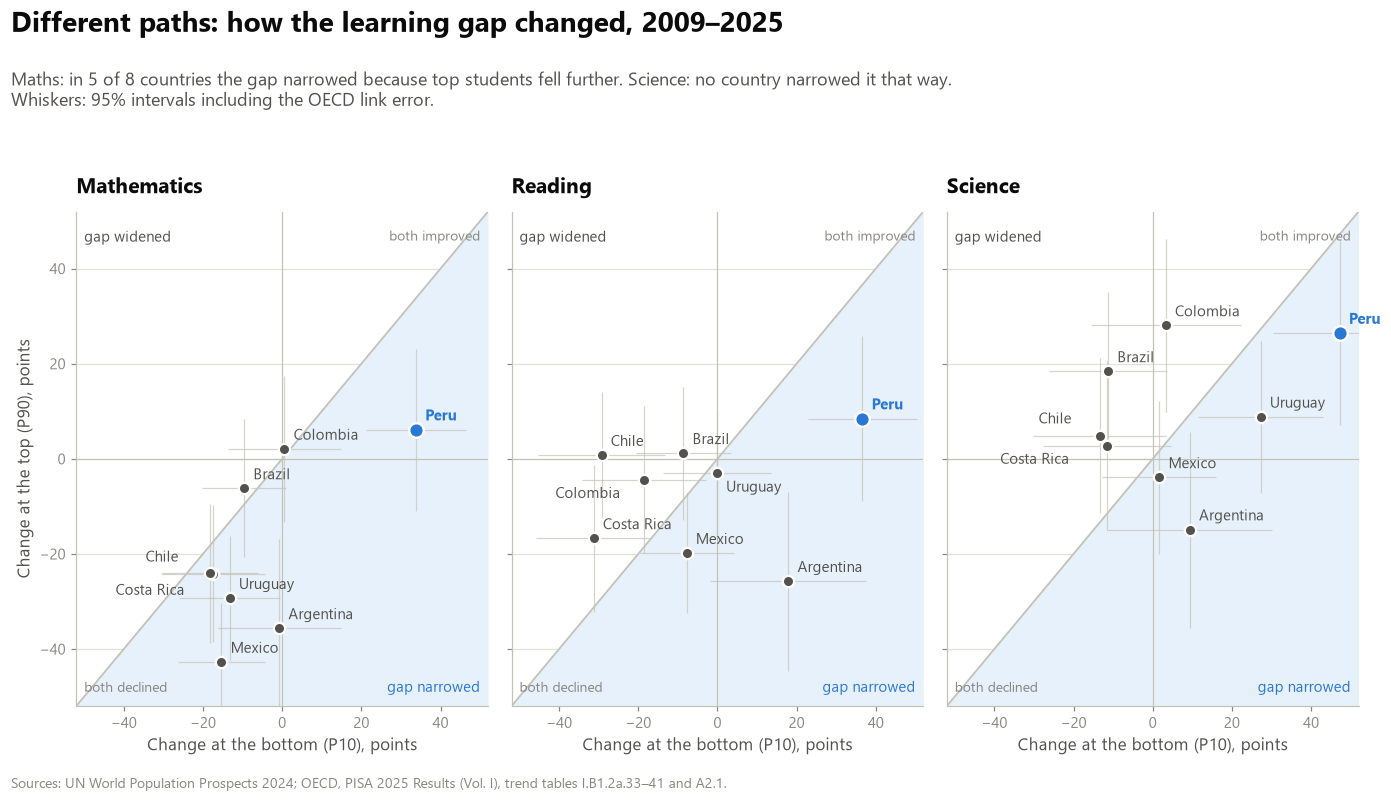

In [3]:
DESPLAZA = {  # posición de las etiquetas para que no se encimen (puntos)
    ("Matematicas", "Chile"): (-44, 8), ("Matematicas", "Costa Rica"): (-62, -14),
    ("Ciencias", "Chile"): (-40, 8), ("Ciencias", "Costa Rica"): (-70, -12),
    ("Lectura", "Uruguay"): (6, -12), ("Lectura", "Colombia"): (-58, -12),
}
fig, axes = plt.subplots(1, 3, figsize=TAMANO, sharex=True, sharey=True)
lim = 52
for ax, materia in zip(axes, MATERIAS):
    d = cambios.loc[cambios["Materia"].eq(materia)]
    ax.fill_between([-lim, lim], [-lim, lim], -lim, color="#e7f1fb", lw=0)
    ax.plot([-lim, lim], [-lim, lim], color=GRIS, lw=1.2)
    ax.axhline(0, color=GRIS, lw=0.8)
    ax.axvline(0, color=GRIS, lw=0.8)
    for _, f in d.iterrows():
        peru = f["Pais"] == "Peru"
        color = DESTACADO if peru else OSCURO
        ax.errorbar(f["dP10"], f["dP90"], xerr=1.96 * f["dP10_se"], yerr=1.96 * f["dP90_se"],
                    fmt="none", ecolor=GRIS, elinewidth=0.8, alpha=0.7, zorder=1)
        ax.scatter(f["dP10"], f["dP90"], s=90 if peru else 55, color=color, edgecolor="white", linewidth=1.5, zorder=3)
        dx, dy = DESPLAZA.get((materia, f["Pais"]), (6, 6))
        ax.annotate(f["Pais"], (f["dP10"], f["dP90"]), textcoords="offset points", xytext=(dx, dy),
                    fontsize=10, color=color, fontweight="bold" if peru else "normal")
    ax.text(lim - 2, -lim + 3, "gap narrowed", ha="right", fontsize=10, color=DESTACADO)
    ax.text(-lim + 2, lim - 4, "gap widened", ha="left", va="top", fontsize=10, color=OSCURO)
    ax.text(lim - 2, lim - 4, "both improved", ha="right", va="top", fontsize=9, color=TEXTO_SUAVE)
    ax.text(-lim + 2, -lim + 3, "both declined", ha="left", fontsize=9, color=TEXTO_SUAVE)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim))
    ax.set_title(MATERIA_EN[materia], fontsize=14)
    ax.set_xlabel("Change at the bottom (P10), points")
axes[0].set_ylabel("Change at the top (P90), points")

fig.suptitle("Different paths: how the learning gap changed, 2009–2025", x=0.01, ha="left", fontsize=18, fontweight="bold", y=0.99)
subtitulo(fig, "Maths: in 5 of 8 countries the gap narrowed because top students fell further. Science: no country narrowed it that way.\nWhiskers: 95% intervals including the OECD link error.")
pie(fig)
fig.tight_layout(rect=(0, 0.03, 1, 0.86))
_ = guardar_figura(fig, "fig02_caminos_distintos")

## Fig 03 · Perú, la excepción

Percentiles 10 y 90 de cada país por ciclo. Perú en azul; los otros 7 países en gris. Argentina 2015 no se muestra (no comparable según la OCDE).

Figura guardada: figures\fig03_peru_excepcion.png


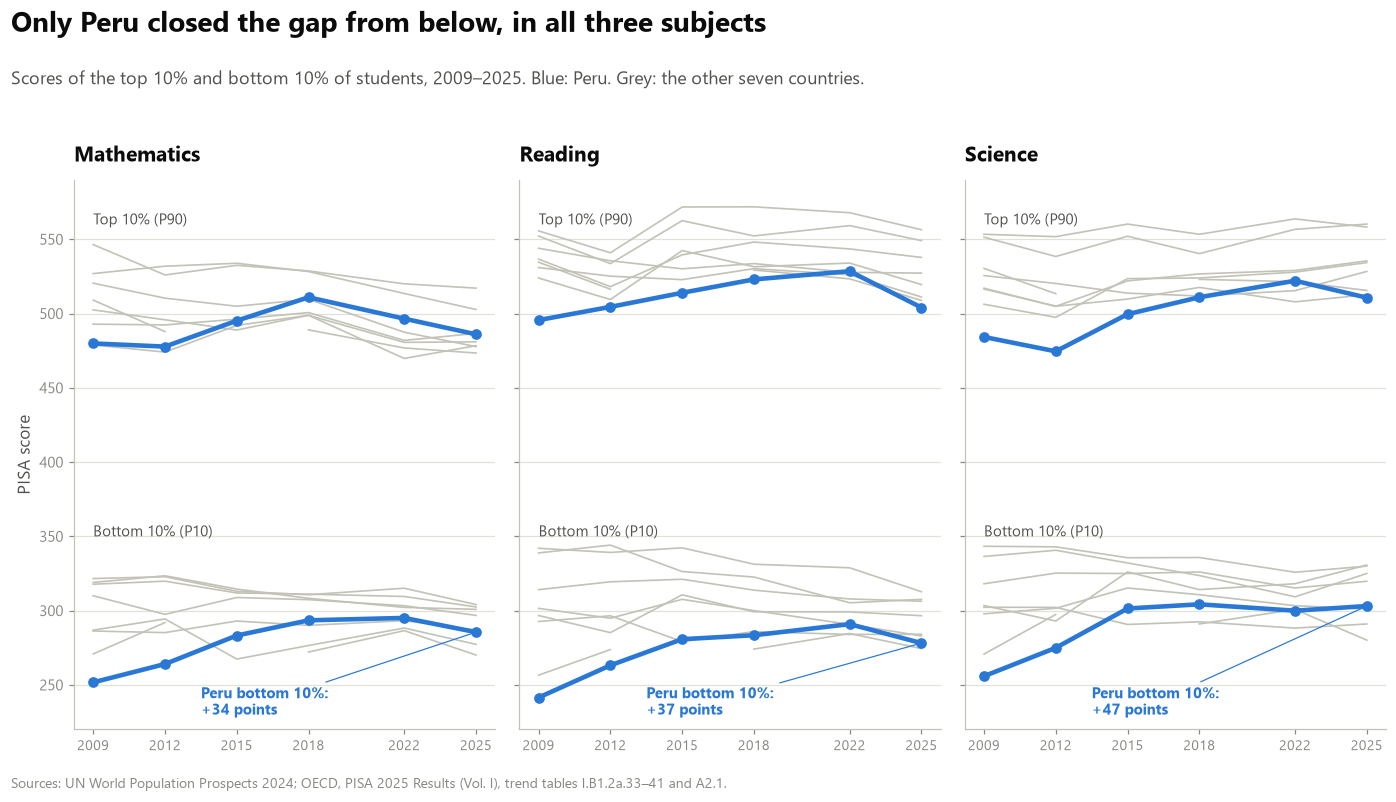

In [4]:
fig, axes = plt.subplots(1, 3, figsize=TAMANO, sharey=True)
ciclos = [2009, 2012, 2015, 2018, 2022, 2025]
for ax, materia in zip(axes, MATERIAS):
    d = panel.loc[panel["Materia"].eq(materia) & panel["Time"].ge(2009)]
    for pais, g in d.groupby("Pais"):
        g = g.sort_values("Time")
        peru = pais == "Peru"
        for perc, estilo in [("P90", "-"), ("P10", "-")]:
            ax.plot(g["Time"], g[perc], color=DESTACADO if peru else GRIS, lw=3 if peru else 1.1,
                    marker="o" if peru else None, ms=6, zorder=3 if peru else 1, ls=estilo)
    peru = d.loc[d["Pais"].eq("Peru")].set_index("Time")
    cambio_p10 = peru.loc[2025, "P10"] - peru.loc[2009, "P10"]
    ax.annotate(f"Peru bottom 10%:\n+{cambio_p10:.0f} points", (2025, peru.loc[2025, "P10"]), xytext=(2013.5, 230),
                fontsize=10, color=DESTACADO, fontweight="bold", arrowprops=dict(arrowstyle="-", color=DESTACADO, lw=0.8))
    ax.text(2009, 560, "Top 10% (P90)", fontsize=10, color=OSCURO)
    ax.text(2009, 350, "Bottom 10% (P10)", fontsize=10, color=OSCURO)
    ax.set_title(MATERIA_EN[materia], fontsize=14)
    ax.set_xticks(ciclos, [str(c) for c in ciclos], rotation=0, fontsize=9)
    ax.set_ylim(220, 590)
axes[0].set_ylabel("PISA score")

fig.suptitle("Only Peru closed the gap from below, in all three subjects", x=0.01, ha="left", fontsize=18, fontweight="bold", y=0.99)
subtitulo(fig, "Scores of the top 10% and bottom 10% of students, 2009–2025. Blue: Peru. Grey: the other seven countries.")
pie(fig)
fig.tight_layout(rect=(0, 0.03, 1, 0.9))
_ = guardar_figura(fig, "fig03_peru_excepcion")

## Fig 04 · Cobertura y demografía

Izquierda: en matemáticas, cambio del percentil 90 observado frente al de toda la generación de 15 años, suponiendo que los jóvenes que PISA no cubre no estarían en el 25 % superior. Derecha: cambio de la fecundidad frente al cambio de la brecha, por materia.

Figura guardada: figures\fig04_cobertura_y_demografia.png


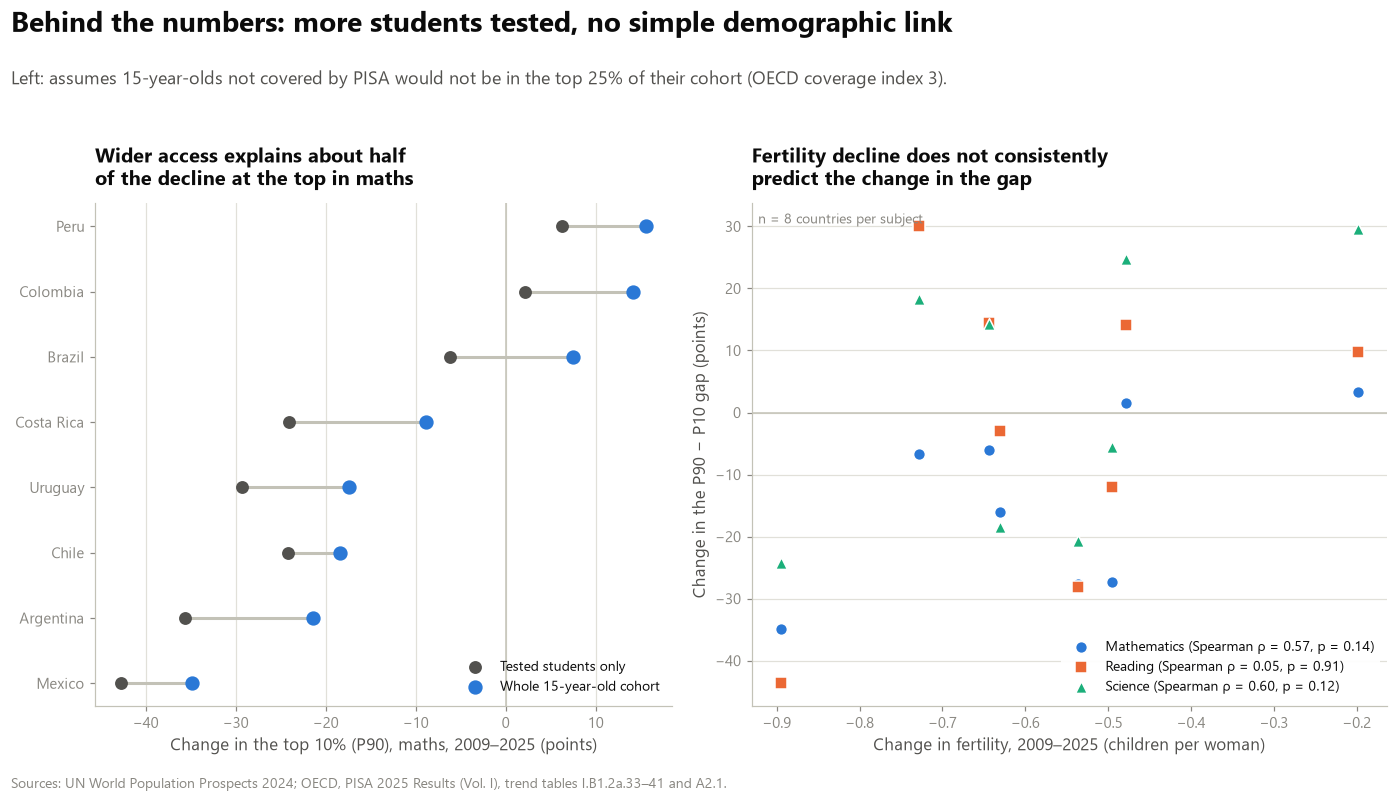

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=TAMANO, gridspec_kw={"width_ratios": [1, 1.1]})

m = cambios.loc[cambios["Materia"].eq("Matematicas")].sort_values("dP90_generacion")
y = np.arange(len(m))
ax1.axvline(0, color=GRIS, lw=1)
for i, (_, f) in enumerate(m.iterrows()):
    ax1.plot([f["dP90_observado"], f["dP90_generacion"]], [i, i], color=GRIS, lw=2, zorder=1)
ax1.scatter(m["dP90_observado"], y, color=OSCURO, s=55, zorder=2, label="Tested students only")
ax1.scatter(m["dP90_generacion"], y, color=DESTACADO, s=70, zorder=3, label="Whole 15-year-old cohort")
ax1.set_yticks(y, m["Pais"])
ax1.grid(axis="y", visible=False)
ax1.grid(axis="x", visible=True)
ax1.set_xlabel("Change in the top 10% (P90), maths, 2009–2025 (points)")
ax1.set_title("Wider access explains about half\nof the decline at the top in maths", fontsize=13)
ax1.legend(loc="lower right", fontsize=9)

marcas = {"Matematicas": "o", "Lectura": "s", "Ciencias": "^"}
ax2.axhline(0, color=GRIS, lw=1)
for k, materia in enumerate(MATERIAS):
    d = cambios.loc[cambios["Materia"].eq(materia)]
    rho, p = stats.spearmanr(d["dTFR"], d["dBrecha"])
    ax2.scatter(d["dTFR"], d["dBrecha"], marker=marcas[materia], s=60, color=PALETA[k], edgecolor="white",
                linewidth=1, label=f"{MATERIA_EN[materia]} (Spearman ρ = {rho:.2f}, p = {p:.2f})")
ax2.set_xlabel("Change in fertility, 2009–2025 (children per woman)")
ax2.set_ylabel("Change in the P90 − P10 gap (points)")
ax2.set_title("Fertility decline does not consistently\npredict the change in the gap", fontsize=13)
ax2.legend(loc="lower right", fontsize=9, frameon=True, facecolor="white", edgecolor="none", framealpha=0.95)
ax2.text(0.01, 0.98, "n = 8 countries per subject", transform=ax2.transAxes, ha="left", va="top", fontsize=9, color=TEXTO_SUAVE)

fig.suptitle("Behind the numbers: more students tested, no simple demographic link", x=0.01, ha="left", fontsize=18, fontweight="bold", y=0.99)
subtitulo(fig, "Left: assumes 15-year-olds not covered by PISA would not be in the top 25% of their cohort (OECD coverage index 3).")
pie(fig)
fig.tight_layout(rect=(0, 0.03, 1, 0.9))
_ = guardar_figura(fig, "fig04_cobertura_y_demografia")